# 05 Triage threshold, then the final test

**The business rule:** the model routes a complaint automatically only when it is confident. Everything else goes to a person.

- **Confidence** = the model's highest probability for that complaint.
- **Threshold t:** auto-route if confidence >= t, otherwise send to a human.
- **Coverage** = share of complaints auto-routed. **Auto-routed accuracy** = share of those that went to the right team.

Raising t sends fewer complaints automatically (lower coverage) but makes fewer mistakes on the ones it does send (higher accuracy). We pick t for a stated target: **95% accuracy on auto-routed complaints**, with as much coverage as possible.

**Order matters:**
1. Choose the model and t on **validation** (Jan 25-31).
2. Then, at the end, apply that model and that t to **test** (February) **once**. After looking at the test numbers we change nothing; otherwise test stops being an honest estimate.

Model: TF-IDF + logistic regression. It beat MiniLM on validation in notebook 04 (macro-F1 0.673 vs 0.598). We compare the default and the balanced version here, because balanced weights change the probabilities, and probabilities are what the threshold uses.

In [1]:
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score, classification_report

ROOT = Path.cwd()
while not (ROOT / "README.md").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed" / "complaints_clean.csv.gz"
FIG = ROOT / "reports" / "figures"
MODELS = ROOT / "models"

df = pd.read_csv(DATA, dtype=str, keep_default_na=False)
valid = df[df["split"] == "valid"]
y_valid = valid["Product"].to_numpy()
print("valid:", len(valid))

models = {
    "default": joblib.load(MODELS / "tfidf_logreg.joblib"),
    "balanced": joblib.load(MODELS / "tfidf_logreg_balanced.joblib"),
}
TARGET = 0.95

valid: 18093


## Probabilities and confidence

`predict_proba` returns one row per complaint and one column per product; each row adds up to 1. The column order is `model.classes_`.
- `argmax` along the row = the predicted product (same as `predict`).
- `max` along the row = the confidence.

In [2]:
def confidence_and_pred(model, texts):
    proba = model.predict_proba(texts)
    pred = model.classes_[proba.argmax(axis=1)]
    conf = proba.max(axis=1)
    return conf, pred

val = {}
for name, m in models.items():
    conf, pred = confidence_and_pred(m, valid["text"])
    val[name] = {"conf": conf, "pred": pred, "correct": pred == y_valid}
    print(f"{name:<9} accuracy if we auto-route everything: {val[name]['correct'].mean():.3f}"
          f" | median confidence {np.median(conf):.2f}")

default   accuracy if we auto-route everything: 0.862 | median confidence 0.93
balanced  accuracy if we auto-route everything: 0.826 | median confidence 0.80


## Is confidence meaningful? Accuracy by confidence band

If higher confidence really means "more likely right", accuracy should rise from band to band. That is what makes a threshold work at all.

In [3]:
BINS = [0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0]
band_tables = {}
for name, v in val.items():
    bands = pd.cut(v["conf"], bins=BINS)
    band_tables[name] = (pd.DataFrame({"band": bands, "correct": v["correct"]})
                           .groupby("band", observed=True)["correct"]
                           .agg(complaints="size", accuracy="mean"))
pd.concat(band_tables, axis=1).round(3)   # default and balanced side by side

default            balanced         
            complaints accuracy complaints accuracy
band                                               
(0.0, 0.4]        1121    0.445       2030    0.489
(0.4, 0.5]         983    0.601       1462    0.642
(0.5, 0.6]        1186    0.641       1618    0.734
(0.6, 0.7]        1245    0.740       1820    0.805
(0.7, 0.8]        1456    0.821       2231    0.870
(0.8, 0.9]        2077    0.889       3329    0.907
(0.9, 0.95]       2077    0.944       2206    0.943
(0.95, 1.0]       7948    0.984       3397    0.976

## The coverage / accuracy curve

For every threshold from 0.10 to 0.99 we compute coverage and auto-routed accuracy. (With 10 classes the top probability is always at least 0.1, so t = 0.10 auto-routes everything.)

In [4]:
def triage_curve(conf, correct, thresholds):
    rows = []
    for t in thresholds:
        auto = conf >= t
        rows.append({"t": round(t, 2),
                     "coverage": auto.mean(),
                     "auto_accuracy": correct[auto].mean() if auto.any() else np.nan,
                     "n_auto": int(auto.sum())})
    return pd.DataFrame(rows)

thresholds = np.arange(0.10, 1.00, 0.01)
curves = {name: triage_curve(v["conf"], v["correct"], thresholds) for name, v in val.items()}
curves["balanced"].iloc[::10].round(3)    # every 10th row, to get a feel for it

,t,coverage,auto_accuracy,n_auto
0,0.1,1.000,0.826,18093
10,0.2,0.994,0.829,17992
20,0.3,0.954,0.845,17261
30,0.4,0.888,0.868,16063
40,0.5,0.807,0.891,14601
50,0.6,0.718,0.911,12983
60,0.7,0.617,0.928,11163
70,0.8,0.494,0.942,8932
80,0.9,0.310,0.963,5603


## Pick t on validation

For each model: the **smallest** t whose auto-routed accuracy is at least 95%. Smallest t = most coverage while still meeting the target. Then we keep the model with the higher coverage at its t.

One safeguard: we require at least 1,000 auto-routed complaints, so a tiny, lucky set can't "meet" the target.

In [5]:
picks = {}
for name, c in curves.items():
    ok = c[(c["auto_accuracy"] >= TARGET) & (c["n_auto"] >= 1000)]
    picks[name] = ok.iloc[0] if len(ok) else None
    print(name, "->", None if picks[name] is None else picks[name].round(3).to_dict())

best = max((n for n in picks if picks[n] is not None), key=lambda n: picks[n]["coverage"])
T = float(picks[best]["t"])
print(f"\nchosen: {best}, t = {T:.2f}")

default -> {'t': 0.73, 'coverage': 0.726, 'auto_accuracy': 0.951, 'n_auto': 13127.0}
balanced -> {'t': 0.85, 'coverage': 0.412, 'auto_accuracy': 0.954, 'n_auto': 7450.0}

chosen: default, t = 0.73


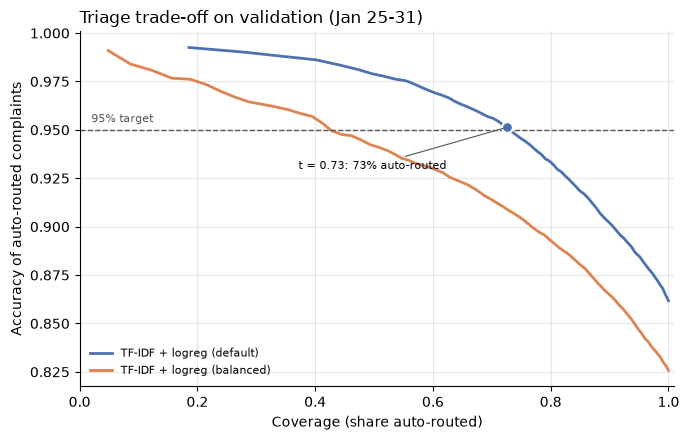

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = {"default": "#4C72B0", "balanced": "#DD8452"}
for name, c in curves.items():
    ax.plot(c["coverage"], c["auto_accuracy"], color=colors[name], lw=2, label=f"TF-IDF + logreg ({name})")
ax.axhline(TARGET, color="#555555", lw=1, ls="--")
ax.text(0.02, TARGET + 0.004, "95% target", fontsize=8, color="#555555")
p = picks[best]
ax.scatter([p["coverage"]], [p["auto_accuracy"]], s=60, color=colors[best], zorder=3,
           edgecolor="white", linewidth=1.5)
ax.annotate(f"t = {T:.2f}: {p['coverage']:.0%} auto-routed", (p["coverage"], p["auto_accuracy"]),
            xytext=(-150, -30), textcoords="offset points", fontsize=8,
            arrowprops=dict(arrowstyle="-", color="#555555", lw=0.8))
ax.set_xlabel("Coverage (share auto-routed)")
ax.set_ylabel("Accuracy of auto-routed complaints")
ax.set_title("Triage trade-off on validation (Jan 25-31)", loc="left")
ax.set_xlim(0, 1.01)
ax.legend(frameon=False, loc="lower left", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "05_triage_curve_valid.png", dpi=150)
plt.show()

## Who gets sent to a human? Per product, on validation

Overall coverage can hide that one product is almost never auto-routed. For each **true** product: what share was auto-routed at t, and how accurate were those.

In [7]:
SHORT = {
    "Credit reporting or other personal consumer reports": "Credit reporting",
    "Money transfer, virtual currency, or money service": "Money transfer",
    "Checking or savings account": "Checking/savings",
    "Debt collection": "Debt collection",
    "Credit card": "Credit card",
    "Mortgage": "Mortgage",
    "Student loan": "Student loan",
    "Vehicle loan or lease": "Vehicle loan",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/personal loan",
    "Other": "Other",
}

def per_product(y, conf, correct, t):
    d = pd.DataFrame({"product": pd.Series(y).map(SHORT), "auto": conf >= t, "correct": correct})
    out = d.groupby("product").agg(complaints=("auto", "size"), coverage=("auto", "mean"))
    out["auto_accuracy"] = d[d["auto"]].groupby("product")["correct"].mean()
    return out.sort_values("complaints", ascending=False).round(3)

per_product(y_valid, val[best]["conf"], val[best]["correct"], T)

,complaints,coverage,auto_accuracy
product,,,
Credit reporting,11566,0.875,0.991
Debt collection,1920,0.465,0.657
Money transfer,1488,0.672,0.989
Checking/savings,1237,0.515,0.901
Credit card,818,0.273,0.673
Mortgage,270,0.274,0.946
Vehicle loan,238,0.172,0.220
Student loan,234,0.385,0.867
Other,177,0.215,0.132


---
# Final evaluation on TEST (run once)

Everything above was decided on validation: the model (`best`) and the threshold (`T`). Now we apply them to February. **Do not go back and change anything after seeing these numbers.**

Expect test to be a bit worse than validation: notebook 02 showed February's product mix differs from January's (time drift).

In [8]:
test = df[df["split"] == "test"]
y_test = test["Product"].to_numpy()
model = models[best]

conf_t, pred_t = confidence_and_pred(model, test["text"])
correct_t = pred_t == y_test
auto_t = conf_t >= T

test_scores = {
    "model": f"tfidf + logreg ({best})",
    "threshold": T,
    "test_rows": int(len(test)),
    "macro_f1": f1_score(y_test, pred_t, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_test, pred_t, average="weighted", zero_division=0),
    "accuracy_all": correct_t.mean(),
    "coverage": auto_t.mean(),
    "auto_accuracy": correct_t[auto_t].mean(),
    "n_auto": int(auto_t.sum()),
    "n_to_human": int((~auto_t).sum()),
    "human_queue_accuracy_if_auto": correct_t[~auto_t].mean(),
}
pd.Series(test_scores).to_frame("test")

,test
model,tfidf + logreg (default)
threshold,0.73
test_rows,42445
macro_f1,0.64931
weighted_f1,0.816689
accuracy_all,0.826953
coverage,0.655413
auto_accuracy,0.934074
n_auto,27819
n_to_human,14626


`human_queue_accuracy_if_auto` answers: "how often would the model have been right on the complaints we sent to people?" If it's low, the threshold is doing its job: it's holding back the complaints the model would have got wrong.

In [9]:
# Validation vs test, side by side
p = picks[best]
pd.DataFrame({
    "valid": {"macro_f1": f1_score(y_valid, val[best]["pred"], average="macro", zero_division=0),
              "coverage": p["coverage"], "auto_accuracy": p["auto_accuracy"]},
    "test": {k: test_scores[k] for k in ["macro_f1", "coverage", "auto_accuracy"]},
}).round(3)

,valid,test
macro_f1,0.653,0.649
coverage,0.726,0.655
auto_accuracy,0.951,0.934


In [10]:
# Per-class report on test (all complaints, before the threshold)
ORDER = [p for p in SHORT if p in set(y_test)]
rep = classification_report(y_test, pred_t, labels=ORDER, output_dict=True, zero_division=0)
t = pd.DataFrame(rep).T.loc[ORDER, ["precision", "recall", "f1-score", "support"]]
t.index = [SHORT[p] for p in t.index]
t["support"] = t["support"].astype(int)
t.round(3)

,precision,recall,f1-score,support
Credit reporting,0.864,0.946,0.903,24740
Money transfer,0.802,0.811,0.807,2906
Checking/savings,0.724,0.802,0.761,3101
Debt collection,0.735,0.616,0.670,5240
Credit card,0.756,0.656,0.703,2710
Mortgage,0.840,0.785,0.812,1005
Student loan,0.864,0.494,0.628,964
Vehicle loan,0.737,0.485,0.585,802
Payday/personal loan,0.734,0.226,0.346,451
Other,0.935,0.163,0.278,526


In [11]:
# Per product on test, at the threshold
per_product(y_test, conf_t, correct_t, T)

,complaints,coverage,auto_accuracy
product,,,
Credit reporting,24740,0.847,0.984
Debt collection,5240,0.435,0.647
Checking/savings,3101,0.394,0.909
Money transfer,2906,0.577,0.964
Credit card,2710,0.289,0.706
Mortgage,1005,0.342,0.956
Student loan,964,0.295,0.683
Vehicle loan,802,0.167,0.455
Other,526,0.213,0.196


## Save

One JSON file with the chosen threshold and the test results, plus the validation curve. These go into `reports/results_summary.md` later.

In [12]:
out = {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in test_scores.items()}
out["chosen_on"] = "validation (2025-01-25 to 2025-01-31)"
out["target_auto_accuracy"] = TARGET
out["valid_coverage"] = round(float(picks[best]["coverage"]), 4)
out["valid_auto_accuracy"] = round(float(picks[best]["auto_accuracy"]), 4)
(ROOT / "reports" / "05_triage_test.json").write_text(json.dumps(out, indent=2))
curves[best].to_csv(ROOT / "reports" / "05_triage_curve_valid.csv", index=False)
print(json.dumps(out, indent=2))

{
  "model": "tfidf + logreg (default)",
  "threshold": 0.73,
  "test_rows": 42445,
  "macro_f1": 0.6493,
  "weighted_f1": 0.8167,
  "accuracy_all": 0.827,
  "coverage": 0.6554,
  "auto_accuracy": 0.9341,
  "n_auto": 27819,
  "n_to_human": 14626,
  "human_queue_accuracy_if_auto": 0.6232,
  "chosen_on": "validation (2025-01-25 to 2025-01-31)",
  "target_auto_accuracy": 0.95,
  "valid_coverage": 0.7255,
  "valid_auto_accuracy": 0.9513
}
